![Banner](../../../../Images/Banner/03_spatial_analysis/03_05_banner_spatial_analysis_Network.png)



# Flow Networks: Commuting, Gravity, and Contagion



## Overview

A **flow network** is a weighted, directed network where nodes are places and edge weights
are volumes moving between them (commuters, migrants, freight, trade). Flow data are
usually stored as an origin-destination (OD) matrix.

This notebook uses the synthetic commuting OD table in `Data/00_shared/data_spatial_net/` with
`geolattice.spatial_analysis.network_analysis` for symmetric flow graphs, gravity-model fit
diagnostics, metapopulation SIR, and arrival times.

Topics:

- OD table → directed weighted graph; in-/out-/net flows
- Flow maps and distance decay
- Gravity models (OLS vs PPML)
- Dominant-flow hierarchy and Louvain functional regions
- Metapopulation SIR on commuting flows



## Setup

The next cell finds the repository root, puts it on the import path, points `DATA` at
`data/data_spatial_net`, and imports `geolattice.spatial_analysis.network_analysis` as `sna`.

**Installation.** This notebook needs installation option 2 (core plus spatial analysis): `pip install "geolattice[analysis]"`. See "Installation options" in the GeoLattice README.

In [3]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

# Standard library imports for path setup and warning control.
import warnings  # silence noisy third-party warnings during demos
from pathlib import Path  # filesystem paths for locating sample data

# Third-party GIS / network / plotting stack used throughout the notebook.
import geopandas as gpd  # GeoDataFrame I/O and geometry ops
import matplotlib.pyplot as plt  # figure and axes creation for maps
import networkx as nx  # graph algorithms and conversions
import numpy as np  # array ops for distances and matrices
import pandas as pd  # tabular display of results
from IPython.display import display  # rich table previews in the notebook

# Hide library warnings so the notebook output stays readable.
warnings.filterwarnings("ignore")  # hide library warnings in notebook output

# ===================================================================
# Setup for spatial network demos.
# Import GeoLattice, point DATA at Data/00_shared/data_spatial_net,
# and import network_analysis as sna.
# ===================================================================

# The installed package lives in src/; the repository root is its parent.
import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    raise FileNotFoundError("Could not find the GeoLattice repository root.")

# Synthetic road / town / tract data used by the network chapter.
DATA = ROOT / "Data" / "00_shared" / "data_spatial_net"  # chapter sample-data folder under the repo

# Spatial network helpers from geolattice.
from geolattice.spatial_analysis import network_analysis as sna  # spatial network helpers aliased as sna

# Compact figures with top/right spines removed for a cleaner look.
plt.rcParams.update(  # compact figures with cleaner spines
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}  # notebook step
)
print("repo:", ROOT)  # status line for the notebook reader
print("data:", DATA)  # status line for the notebook reader
print("networkx", nx.__version__, "| geopandas", gpd.__version__)  # status line for the notebook reader

# Flow-map arrows, gravity estimators, and optional OSMnx utilities.
import osmnx as ox  # available if a cell needs graph_to_gdfs
from matplotlib.patches import FancyArrowPatch  # curved OD arrows on flow maps
from sklearn.linear_model import PoissonRegressor, LinearRegression  # PPML vs OLS gravity

# Commuting OD table and town points (indexed by town name).
od = pd.read_csv(DATA / "commuting_od.csv")  # origin-destination commuting volumes
towns = gpd.read_file(DATA / "towns.geojson").set_index("town")  # town points used as routing / flow places
print(f"{len(od)} OD pairs, {od.commuters.sum():,} daily commuters")  # status line for the notebook reader
od.sort_values("commuters", ascending=False).head()  # run this analysis or plotting step



repo: /home/zia207/Github/GeoLattice
data: /home/zia207/Github/GeoLattice/Data/00_shared/data_spatial_net
networkx 3.6.1 | geopandas 1.1.4
380 OD pairs, 37,087 daily commuters


,origin,destination,commuters
57,Eastbrook,Centerville,1813
76,Westover,Centerville,1481
38,Southport,Centerville,1279
2,Centerville,Eastbrook,1246
228,Hillcrest,Centerville,1064


## Travel time between towns

Gravity models need a cost term. We compute fastest drive time on the road network (the same method as 03.06.2).



In [2]:
# ===================================================================
# Attach network travel times and Euclidean km to every OD pair.
# Gravity models use minutes as the cost term.
# ===================================================================

G = sna.load_road_graph(DATA / "roads.graphml")  # road MultiDiGraph
G = sna.prepare_travel_times(  # impute speeds and edge travel times
    G,  # notebook step
    hwy_speeds={"residential": 50, "tertiary": 60, "secondary": 70, "primary": 90},  # fallback speeds by highway class
    minutes_attr=None,  # keep travel_time in seconds on edges
)
towns["node"] = sna.snap_points_to_nodes(towns, G)  # snap each town to a junction
# One Dijkstra per origin town -> seconds to every network node.
tt = {  # define tt
    o: nx.single_source_dijkstra_path_length(G, towns.loc[o, "node"], weight="travel_time")  # run this analysis or plotting step
    for o in towns.index  # notebook step
}
# OD travel time in minutes between snapped town nodes.
od["minutes"] = [tt[o][towns.loc[d, "node"]] / 60 for o, d in zip(od.origin, od.destination)]  # run this analysis or plotting step
# Straight-line km between town geometries (projected CRS).
od["km"] = [  # notebook step
    towns.loc[o, "geometry"].distance(towns.loc[d, "geometry"]) / 1000  # run this analysis or plotting step
    for o, d in zip(od.origin, od.destination)  # run this analysis or plotting step
]
od.head()  # run this analysis or plotting step



,origin,destination,commuters,minutes,km
0,Centerville,Northfield,515,9.463830,13.886959
1,Centerville,Southport,795,9.300604,13.746699
2,Centerville,Eastbrook,1246,9.577395,14.217855
3,Centerville,Westover,979,9.506079,14.062439
4,Centerville,Maple Falls,349,18.346321,14.382478


## Part A: The OD matrix as a directed weighted graph



In [3]:
# ===================================================================
# Build a directed weighted commuting graph and town flow balances.
# in/out ratio > 1 marks employment centres (net importers of workers).
# ===================================================================

# Directed edges for positive commuting volumes only.
F = nx.from_pandas_edgelist(  # directed weighted flow graph
    od[od.commuters > 0],  # notebook step
    "origin",  # continue string literal
    "destination",  # continue string literal
    edge_attr=["commuters", "minutes", "km"],  # edge attributes copied from the table
    create_using=nx.DiGraph,  # graph class (DiGraph / MultiDiGraph / ...)
)
nx.set_node_attributes(F, towns.population.to_dict(), "population")  # run this analysis or plotting step

# Weighted in-/out-degree = total commuting volume.
flows = pd.DataFrame({  # town in-/out-/net-flow balance table
    "population": towns.population,  # continue string literal
    "outflow": pd.Series(dict(F.out_degree(weight="commuters"))),  # continue multi-line call
    "inflow": pd.Series(dict(F.in_degree(weight="commuters"))),  # continue multi-line call
})
flows["net_inflow"] = flows.inflow - flows.outflow  # notebook step
flows["in_out_ratio"] = (flows.inflow / flows.outflow).round(2)  # run this analysis or plotting step
flows.sort_values("net_inflow", ascending=False)  # run this analysis or plotting step



,population,outflow,inflow,net_inflow,in_out_ratio
Centerville,85000,8762,13897,5135,1.59
Elmwood,11107,1024,998,-26,0.97
Stonebridge,14240,1403,1346,-57,0.96
Lakeview,8655,1006,908,-98,0.90
Pine Hollow,12060,1771,1644,-127,0.93
Riverton,4852,633,501,-132,0.79
Ashford,8986,1253,1096,-157,0.87
Oak Grove,12475,2000,1837,-163,0.92
Cedar Ridge,8179,1372,1181,-191,0.86
Millbrook,1906,435,237,-198,0.54


An **in/out ratio** above 1 marks an employment center (net importer of workers); below 1 marks a dormitory town. Centerville is the dominant importer, the classic monocentric pattern.

### OD matrix heatmap



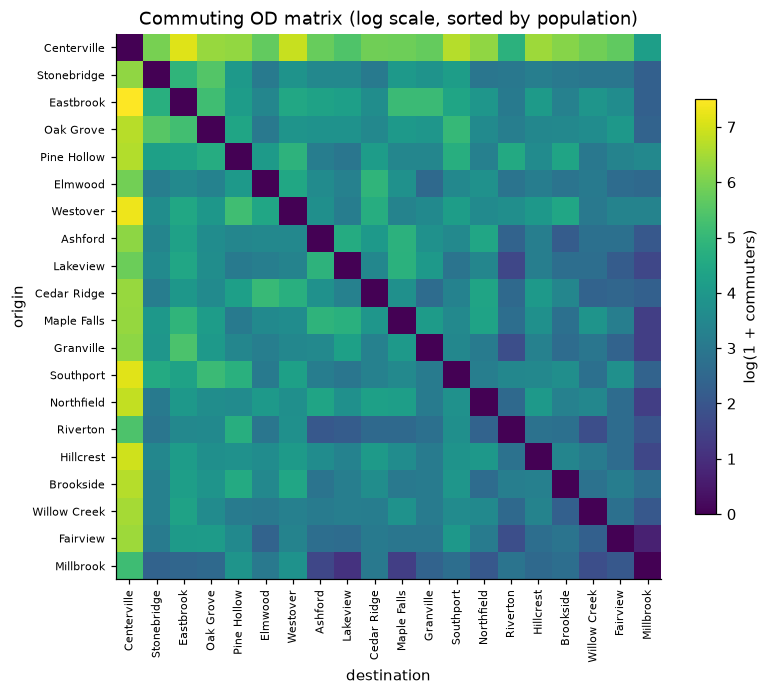

In [4]:
# ===================================================================
# Log-scaled OD heatmap with towns ordered by population.
# ===================================================================

M = od.pivot(index="origin", columns="destination", values="commuters").fillna(0)  # pivoted OD / distance matrix
order = towns.population.sort_values(ascending=False).index  # largest towns first
M = M.loc[order, order]  # pivoted OD / distance matrix
fig, ax = plt.subplots(figsize=(8, 7))  # create figure and primary axes
im = ax.imshow(np.log1p(M.values), cmap="viridis")  # log1p keeps zeros visible
ax.set_xticks(range(len(order)), order, rotation=90, fontsize=7)  # configure or hide x tick labels
ax.set_yticks(range(len(order)), order, fontsize=7)  # configure or hide y tick labels
ax.set(  # set labels, title, or axis limits
    xlabel="destination",  # x-axis label
    ylabel="origin",  # y-axis label
    title="Commuting OD matrix (log scale, sorted by population)",  # plot or map title
)
plt.colorbar(im, ax=ax, label="log(1 + commuters)", shrink=0.7)  # attach a colour bar
plt.show()  # render the figure in the notebook



## Part B: Flow maps

Drawing all 380 flows produces a hairball. Two standard remedies: show only flows above a threshold (or the top *n*), and use curved arrows so A→B and B→A do not overlap.



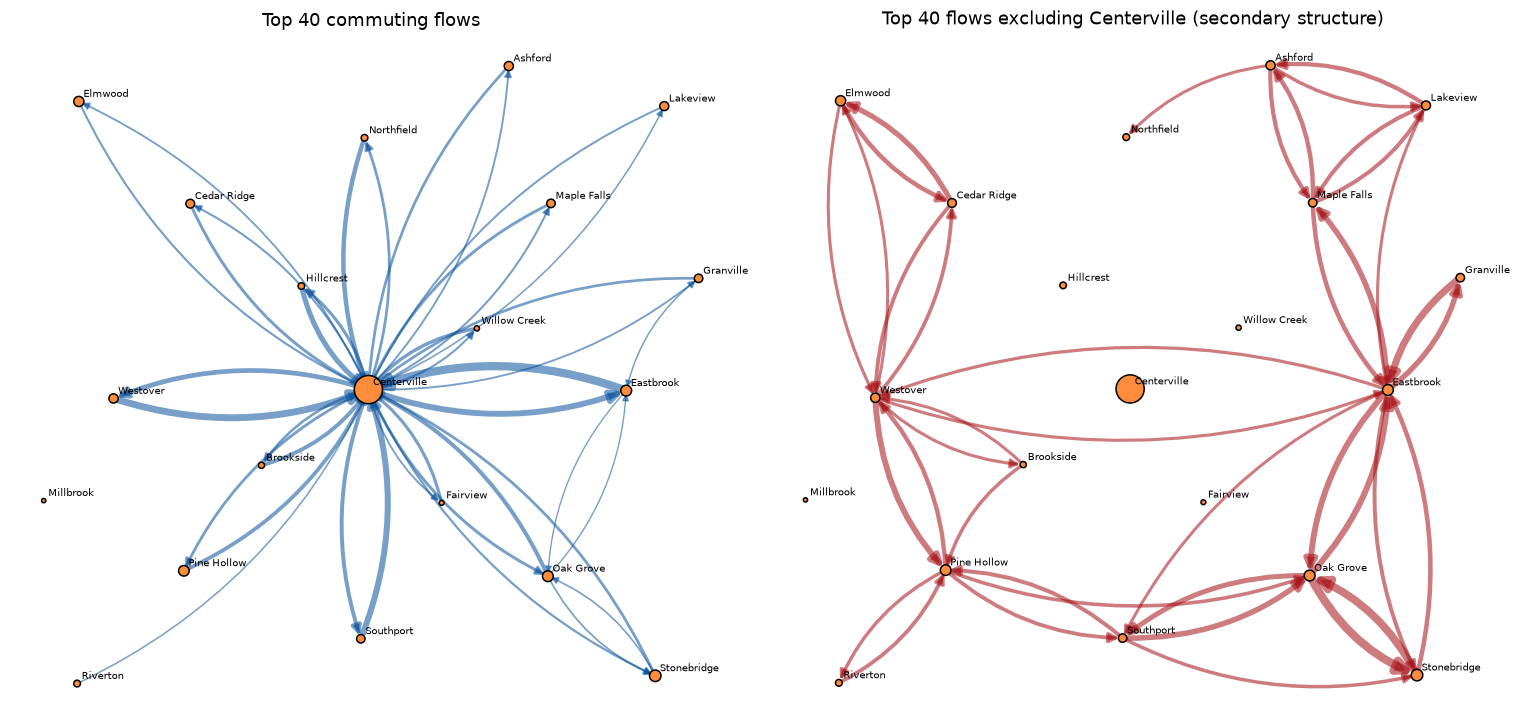

In [5]:
# ===================================================================
# Flow maps: top-n curved arrows, with and without Centerville.
# Filtering the hub reveals secondary commuting sub-systems.
# ===================================================================

def flow_map(ax, df, top=40, color="#08519c", title=""):
    """Draw the largest commuting flows as curved arrows on town locations."""
    sub = df.nlargest(top, "commuters")  # keep only the largest OD pairs
    wmax = sub.commuters.max()  # scale arrow size relative to the largest flow
    for r in sub.itertuples():  # iterate GeoDataFrame rows as named tuples
        p0, p1 = towns.loc[r.origin, "geometry"], towns.loc[r.destination, "geometry"]  # notebook step
        ax.add_patch(FancyArrowPatch(  # add a shape / arrow patch to the axes
            (p0.x, p0.y), (p1.x, p1.y),  # continue multi-line call
            connectionstyle="arc3,rad=0.18",  # curve so A->B and B->A separate
            arrowstyle="-|>",  # arrow head style
            mutation_scale=8 + 10 * r.commuters / wmax,  # head size ~ volume
            lw=0.4 + 5 * r.commuters / wmax,  # stroke width ~ volume
            color=color,  # artist colour
            alpha=0.55,  # regularisation strength (0 = unpenalised PPML)
        ))
    # Town markers sized by population.
    ax.scatter(  # plot point markers
        towns.geometry.x, towns.geometry.y,  # notebook step
        s=towns.population / 250, color="#fd8d3c", edgecolor="k", zorder=3,  # marker size
    )
    for t, p in towns.geometry.items():  # iterate key/value pairs
        ax.annotate(t, (p.x, p.y), fontsize=6.5, xytext=(3, 3), textcoords="offset points")  # label a feature near its coordinates
    ax.set_title(title)  # panel / map title
    ax.set_aspect("equal")  # keep geographic proportions undistorted
    ax.set_axis_off()  # hide coordinate ticks for a clean map

fig, axes = plt.subplots(1, 2, figsize=(14, 6.8))  # create a grid of subplot axes
flow_map(axes[0], od, top=40, title="Top 40 commuting flows")  # run this analysis or plotting step
flow_map(  # continue multi-line call
    axes[1],  # notebook step
    od[(od.origin != "Centerville") & (od.destination != "Centerville")],  # continue multi-line call
    top=40,  # top argument
    color="#a50f15",  # artist colour
    title="Top 40 flows excluding Centerville (secondary structure)",  # plot or map title
)
plt.tight_layout()  # reduce wasted whitespace between panels
plt.show()  # render the figure in the notebook



Removing the dominant node reveals **secondary sub-systems**: smaller towns exchange workers with nearby mid-sized centers. Filtering out a hub is a simple but powerful trick for any flow map.

## Part C: Distance decay and gravity models

The gravity model of spatial interaction:

$$T_{ij} = k\, \frac{P_i^{\alpha} P_j^{\beta}}{f(c_{ij})}, \qquad f(c) = c^{\gamma}\ \text{(power)} \ \text{or}\ e^{\gamma c}\ \text{(exponential)}$$

Taking logs gives a linear model, but **OLS on log flows** has two well-known problems: it must drop zero flows, and it is biased under heteroskedasticity. **Poisson pseudo-maximum likelihood (PPML)** (Santos Silva & Tenreyro, 2006) keeps zeros and is the modern default for trade and migration flows.



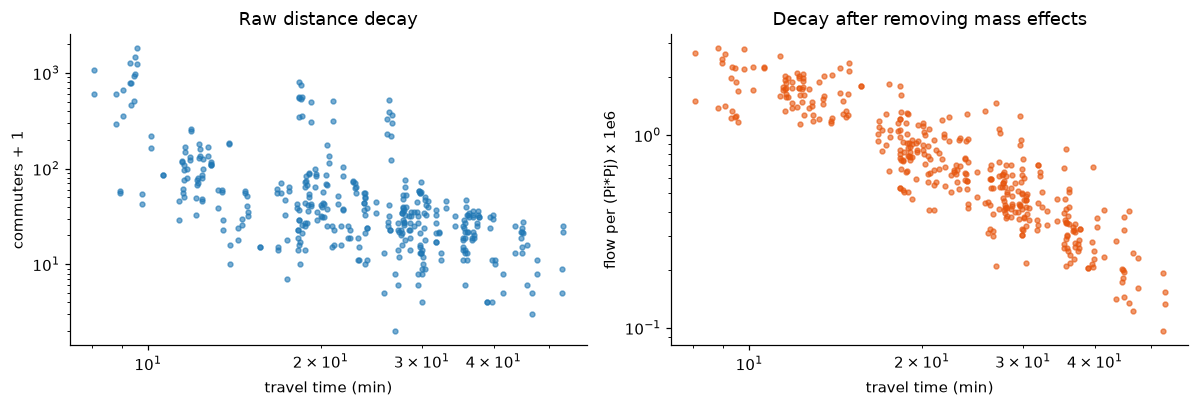

In [6]:
# ===================================================================
# Distance-decay scatters: raw flows vs mass-normalised flows.
# ===================================================================

od["Pi"] = od.origin.map(towns.population)  # origin population mass
od["Pj"] = od.destination.map(towns.population)  # destination population mass
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))  # create a grid of subplot axes
axes[0].scatter(od.minutes, od.commuters + 1, s=10, alpha=0.6)  # scatter points on the axes
axes[0].set(  # configure this subplot's labels or title
    xscale="log", yscale="log",  # xscale argument
    xlabel="travel time (min)", ylabel="commuters + 1", title="Raw distance decay",  # x-axis label
)
# Remove mass effects so the cost term's shape is easier to see.
od["norm"] = od.commuters / (od.Pi * od.Pj) * 1e6  # run this analysis or plotting step
axes[1].scatter(od.minutes, od.norm + 1e-3, s=10, alpha=0.6, color="#e6550d")  # scatter points on the axes
axes[1].set(  # configure this subplot's labels or title
    xscale="log", yscale="log",  # xscale argument
    xlabel="travel time (min)", ylabel="flow per (Pi*Pj) x 1e6",  # x-axis label
    title="Decay after removing mass effects",  # plot or map title
)
plt.tight_layout()  # reduce wasted whitespace between panels
plt.show()  # render the figure in the notebook



In [7]:
# ===================================================================
# Gravity coefficients: OLS on log flows (zeros dropped) vs PPML.
# PPML keeps zero flows and is the modern default for OD models.
# ===================================================================

X = np.c_[np.log(od.Pi), np.log(od.Pj), np.log(od.minutes)]  # design matrix
names = ["log P_origin (alpha)", "log P_dest (beta)", "log minutes (gamma)"]  # coefficient or town name labels

pos = od.commuters > 0  # OLS cannot take log of zero flows
ols = LinearRegression().fit(X[pos], np.log(od.commuters[pos]))  # OLS gravity fit on positive log flows
ppml = PoissonRegressor(alpha=0, max_iter=1000).fit(X, od.commuters)  # keep zeros

coef = pd.DataFrame(  # side-by-side gravity coefficients
    {  # notebook step
        "OLS (log flows, zeros dropped)": ols.coef_,  # continue multi-line call
        "PPML (Poisson, zeros kept)": ppml.coef_,  # continue multi-line call
    },
    index=names,  # index argument
)
print(f"OLS drops {(~pos).sum()} zero flows")  # status line for the notebook reader
coef.round(3)  # run this analysis or plotting step



OLS drops 0 zero flows


,"OLS (log flows, zeros dropped)","PPML (Poisson, zeros kept)"
log P_origin (alpha),0.740,0.754
log P_dest (beta),0.946,0.945
log minutes (gamma),-1.477,-1.370


Fit (squared correlation, all pairs):  PPML 0.998   OLS 0.994


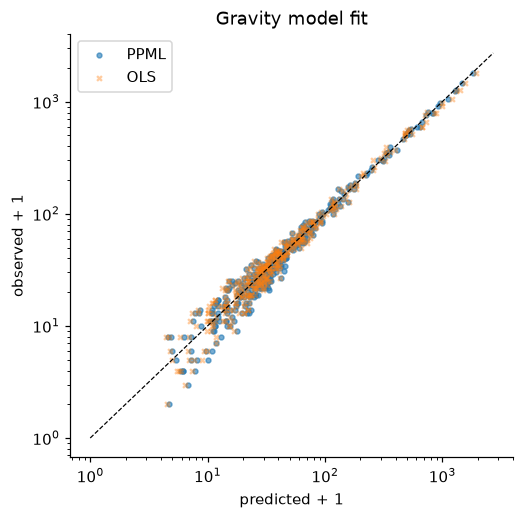

In [8]:
# ===================================================================
# Predicted vs observed flows for PPML and OLS gravity fits.
# ===================================================================

od["pred_ppml"] = ppml.predict(X)  # PPML predictions on the original scale
od["pred_ols"] = np.exp(ols.predict(X))  # exponentiate log-OLS predictions
print(  # status line for the notebook reader
    f"Fit (squared correlation, all pairs):  PPML {sna.pseudo_r2(od.commuters, od.pred_ppml):.3f}   "  # call a geolattice.network_analysis helper
    f"OLS {sna.pseudo_r2(od.commuters, od.pred_ols):.3f}"  # call a geolattice.network_analysis helper
)

fig, ax = plt.subplots(figsize=(5.2, 5))  # create figure and primary axes
ax.scatter(od.pred_ppml + 1, od.commuters + 1, s=10, alpha=0.6, label="PPML")  # plot point markers
ax.scatter(od.pred_ols + 1, od.commuters + 1, s=10, alpha=0.4, label="OLS", marker="x")  # plot point markers
lim = [1, od.commuters.max() * 1.5]  # axis limit or symmetric colour scale
ax.plot(lim, lim, "k--", lw=0.8)  # perfect-fit reference
ax.set(xscale="log", yscale="log", xlabel="predicted + 1", ylabel="observed + 1", title="Gravity model fit")  # set labels, title, or axis limits
ax.legend()  # add a legend for mapped layers
plt.show()  # render the figure in the notebook



The data were generated with exponents of roughly 0.75 (origin), 0.95 (destination) and -1.8 on (time + 5 minutes), so we can check how well each estimator recovers them. The fitted time exponent is flatter than -1.8 because we regress on log(time) rather than log(time + 5): a reminder that the functional form of the cost term matters. Residuals are informative too: pairs with far more commuters than the gravity model predicts point to connections the model does not capture (a shared employer, a fast highway, a cultural tie).



In [9]:
# ===================================================================
# Largest positive residuals vs PPML: pairs with unexpectedly high flow.
# ===================================================================

od["resid_ratio"] = (od.commuters + 1) / (od.pred_ppml + 1)  # observed / predicted
od.sort_values("resid_ratio", ascending=False)[  # run this analysis or plotting step
    ["origin", "destination", "commuters", "pred_ppml", "minutes"]  # notebook step
].head(6).round(1)  # run this analysis or plotting step



,origin,destination,commuters,pred_ppml,minutes
189,Willow Creek,Millbrook,7,3.6,29.6
184,Willow Creek,Riverton,12,6.8,35.6
372,Millbrook,Fairview,7,3.9,26.9
105,Maple Falls,Fairview,24,14.3,22.3
277,Riverton,Fairview,13,7.7,27.2
373,Millbrook,Hillcrest,12,7.4,25.8


## Part D: Hierarchy and regions from flows

### D1. Dominant-flow (Nystuen-Dacey) nodal regions

Each town sends its **largest outflow** to one destination. If that destination is larger than the town itself, the town is *subordinate* to it; otherwise the town is a *central place*. Following these links produces a tree (or forest) that reveals the urban hierarchy.



Central places (no dominant flow to a larger town): ['Centerville']


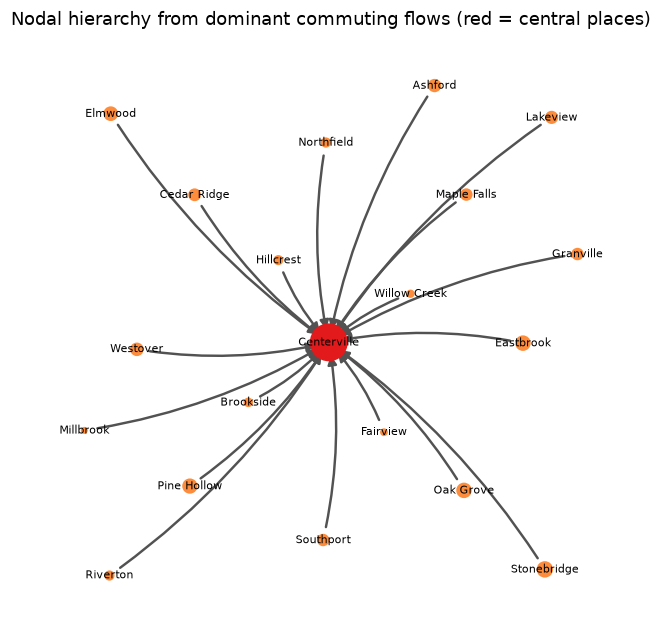

In [10]:
# ===================================================================
# Nystuen-Dacey dominant-flow hierarchy among towns.
# Subordinate towns point to a larger destination that receives their
# largest outflow; sinks of that digraph are central places.
# ===================================================================

# Each origin's single largest outflow destination.
dom = od.loc[od.groupby("origin").commuters.idxmax(), ["origin", "destination", "commuters"]]  # each origin's single largest outflow
# Keep only links to a larger town (true dominant-flow subordination).
dom["dest_larger"] = dom.destination.map(towns.population) > dom.origin.map(towns.population)  # run this analysis or plotting step
T = nx.DiGraph()  # travel-time matrix or time budget
T.add_edges_from(dom.loc[dom.dest_larger, ["origin", "destination"]].itertuples(index=False))  # add graph elements
T.add_nodes_from(towns.index)  # add graph elements
centers = [n for n in T if T.out_degree(n) == 0]  # no dominant flow to a larger town
print("Central places (no dominant flow to a larger town):", centers)  # status line for the notebook reader

fig, ax = plt.subplots(figsize=(7, 7))  # create figure and primary axes
posg = {t: (p.x, p.y) for t, p in towns.geometry.items()}  # geographic layout
nx.draw_networkx_edges(  # draw the NetworkX graph
    T, posg, ax=ax, arrowstyle="-|>", arrowsize=12, width=1.6, edge_color="#525252",  # notebook step
    connectionstyle="arc3,rad=0.1",  # curve style so opposing arrows separate
)
nx.draw_networkx_nodes(  # draw the NetworkX graph
    T, posg, ax=ax,  # notebook step
    node_size=towns.population.reindex(list(T)) / 150,  # hide or size junction markers
    node_color=["#e31a1c" if n in centers else "#fd8d3c" for n in T],  # NetworkX node colour
)
nx.draw_networkx_labels(T, posg, ax=ax, font_size=7)  # draw the NetworkX graph
ax.set_title("Nodal hierarchy from dominant commuting flows (red = central places)")  # panel / map title
ax.set_axis_off()  # hide coordinate ticks for a clean map
plt.show()  # render the figure in the notebook



### D2. Functional regions with community detection

Community detection on the flow network finds groups of towns that exchange more workers among themselves than expected: **functional regions** (the logic behind US commuting zones and labor market areas). We symmetrise flows and compare two weightings:

- **Raw flows** $w_{ij} = T_{ij} + T_{ji}$.
- **Relative flows** $w_{ij} = (T_{ij} + T_{ji}) / \min(P_i, P_j)$, the normalisation used by Tolbert & Sizer (1996) to build US commuting zones. It asks how important the link is *to the smaller place*, which stops a dominant city from absorbing every region.



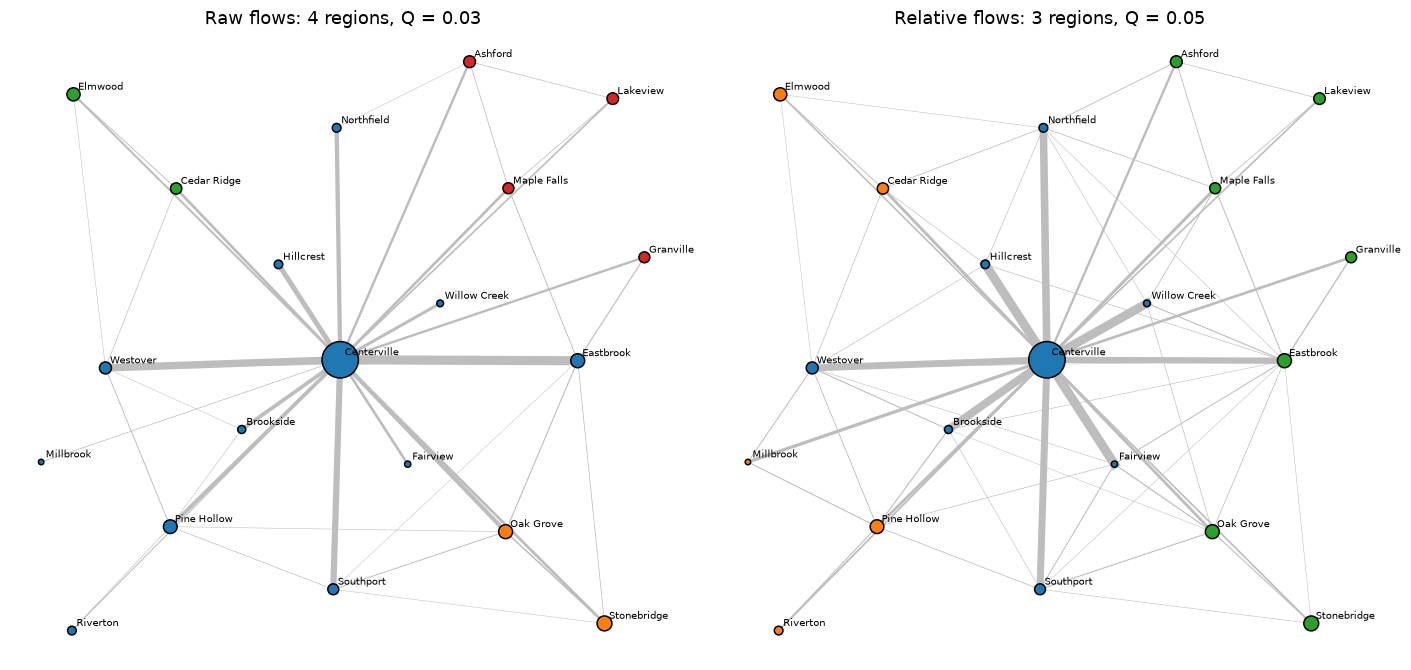

In [11]:
# ===================================================================
# Louvain regions on symmetric flow graphs: raw vs relative flows.
# Relative normalisation down-weights links that are large only because
# both towns are large.
# ===================================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 6.2))  # create a grid of subplot axes
cmap = plt.get_cmap("tab10")  # categorical colormap for communities
for ax, norm in zip(axes, [False, True]):  # iterate paired sequences together
    U = sna.symmetric_flow_graph(od, normalise=norm)  # undirected flow weights
    comms = nx.community.louvain_communities(U, weight="weight", resolution=1.0, seed=3)  # comms argument
    lab = {n: i for i, c in enumerate(comms) for n in c}  # node -> community id
    Q = nx.community.modularity(U, comms, weight="weight")  # Q argument
    wmax = max(d["weight"] for _, _, d in U.edges(data=True))  # wmax argument
    # Draw only relatively strong links to reduce clutter.
    for u, v, d in U.edges(data=True):  # iterate over the collection
        if d["weight"] > 0.05 * wmax:  # conditional branch
            ax.plot(*zip(posg[u], posg[v]), color="#bdbdbd", lw=6 * d["weight"] / wmax, zorder=1)  # draw lines or edges on the axes
    ax.scatter(  # plot point markers
        [posg[n][0] for n in U], [posg[n][1] for n in U],  # notebook step
        s=towns.population.reindex(list(U)) / 150,  # marker size
        c=[cmap(lab[n]) for n in U], edgecolor="k", zorder=2,  # colour values or constant colour
    )
    for n in U:  # iterate over the collection
        ax.annotate(n, posg[n], fontsize=6.5, xytext=(3, 3), textcoords="offset points")  # label a feature near its coordinates
    ax.set_title(f"{'Relative' if norm else 'Raw'} flows: {len(comms)} regions, Q = {Q:.2f}")  # panel / map title
    ax.set_aspect("equal")  # keep geographic proportions undistorted
    ax.set_axis_off()  # hide coordinate ticks for a clean map
plt.tight_layout()  # reduce wasted whitespace between panels
plt.show()  # render the figure in the notebook



Two lessons:

1. **Low modularity is a finding, not a failure.** This region is strongly monocentric, so almost every town is tied mainly to Centerville and no partition separates the flows cleanly. Report Q alongside any map of "functional regions".
2. **Normalisation changes the answer.** Relative flows let smaller towns' local ties count, producing geographically coherent western, central and eastern regions even though nothing in the algorithm knows the coordinates. Distance decay built into the flows makes regions compact; where a region is *not* compact, look for a corridor or a non-spatial tie.

### D3. Flow-weighted centrality

Weighted **PageRank** on the commuting graph rewards towns that receive flows from towns that themselves receive flows: a measure of regional attraction that goes beyond raw inflow.



In [12]:
# ===================================================================
# PageRank on the directed commuting graph vs raw inflow ranking.
# ===================================================================

pr = nx.pagerank(F, weight="commuters")  # importance via recursive inflow
cent = pd.DataFrame({  # tract centroids (or related centre geometry)
    "population": towns.population,  # continue string literal
    "inflow": flows.inflow,  # continue string literal
    "PageRank": pd.Series(pr),  # continue multi-line call
})
cent["inflow rank"] = cent.inflow.rank(ascending=False).astype(int)  # run this analysis or plotting step
cent["PageRank rank"] = cent.PageRank.rank(ascending=False).astype(int)  # run this analysis or plotting step
cent = cent.sort_values("PageRank", ascending=False)  # tract centroids (or related centre geometry)
cent.head(8).round(3)  # run this analysis or plotting step



,population,inflow,PageRank,inflow rank,PageRank rank
Centerville,85000,13897,0.296,1,1
Eastbrook,12548,2751,0.076,2,2
Westover,9215,2009,0.058,3,3
Oak Grove,12475,1837,0.051,4,4
Southport,7621,1721,0.050,5,5
Pine Hollow,12060,1644,0.047,6,6
Stonebridge,14240,1346,0.039,7,7
Maple Falls,7722,1300,0.038,8,8


## Part E: Flows as pathways for contagion

Commuting networks are among the strongest predictors of how infections spread between places. A **metapopulation SIR model** treats each town as a well-mixed population and couples towns through travel.

For town *i*, the force of infection combines local and imported contact:

$$\lambda_i = \beta \sum_j M_{ij} \frac{I_j}{N_j}, \qquad M_{ij} = \begin{cases} 1 - \sum_{k \ne i} m_{ik} & i = j \\ m_{ij} & i \ne j \end{cases}$$

where $m_{ij}$ is the share of *i*'s residents' contact time spent in *j*. We approximate it as 10% of the commuting share (commuters spend part of their day, and part of their contacts, at the destination). We seed one case in the peripheral town of Riverton and record the day each town's prevalence first exceeds 1 in 10,000.



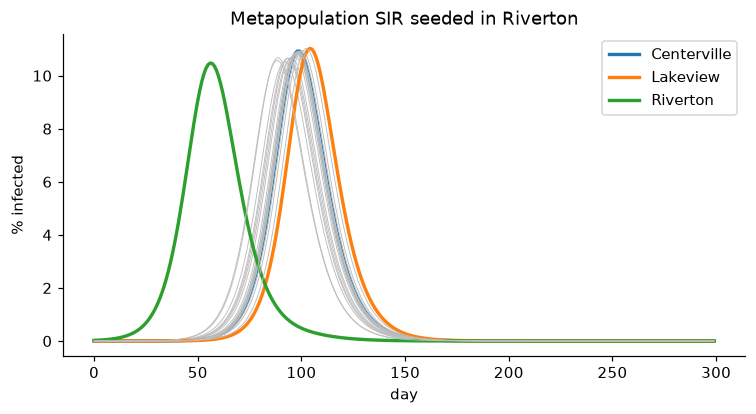

In [13]:
# ===================================================================
# Metapopulation SIR on the commuting matrix, seeded in Riverton.
# Plot infection curves; highlight seed, Centerville, and Lakeview.
# ===================================================================

names_t = list(towns.index)  # stable town order for matrix axes
N = towns.population.reindex(names_t).values.astype(float)  # population vector
C = (  # square commuting matrix
    od.pivot(index="origin", columns="destination", values="commuters")  # run this analysis or plotting step
    .reindex(index=names_t, columns=names_t)  # run this analysis or plotting step
    .fillna(0)  # run this analysis or plotting step
    .values  # notebook step
)  # square commuting matrix aligned with names_t

seed = "Riverton"  # contagion / SIR seed place or farmer set
H = sna.metapopulation_sir(C, N, names_t.index(seed))  # prevalence over time by town
arr = sna.arrival_times(H, threshold=1e-4, index=names_t)  # first day above threshold

fig, ax = plt.subplots(figsize=(8, 3.8))  # create figure and primary axes
for i, t in enumerate(names_t):  # iterate with a numeric index
    hl = t in (seed, "Centerville", "Lakeview")  # highlight a few towns
    ax.plot(H[:, i] * 100, lw=2.2 if hl else 0.6, color=None if hl else "#bdbdbd", label=t if hl else None)  # draw lines or edges on the axes
ax.set(xlabel="day", ylabel="% infected", title=f"Metapopulation SIR seeded in {seed}")  # set labels, title, or axis limits
ax.legend()  # add a legend for mapped layers
plt.show()  # render the figure in the notebook



### Geography vs. network shortcuts

Because these commuting flows decay with distance, arrival time tracks geographic distance from the seed closely. Now add a **long-range tie**: 200 daily trips each way between Riverton and Lakeview, at opposite corners of the region (think of a large employer running a shuttle, or a regional school). Geographically nothing has changed.



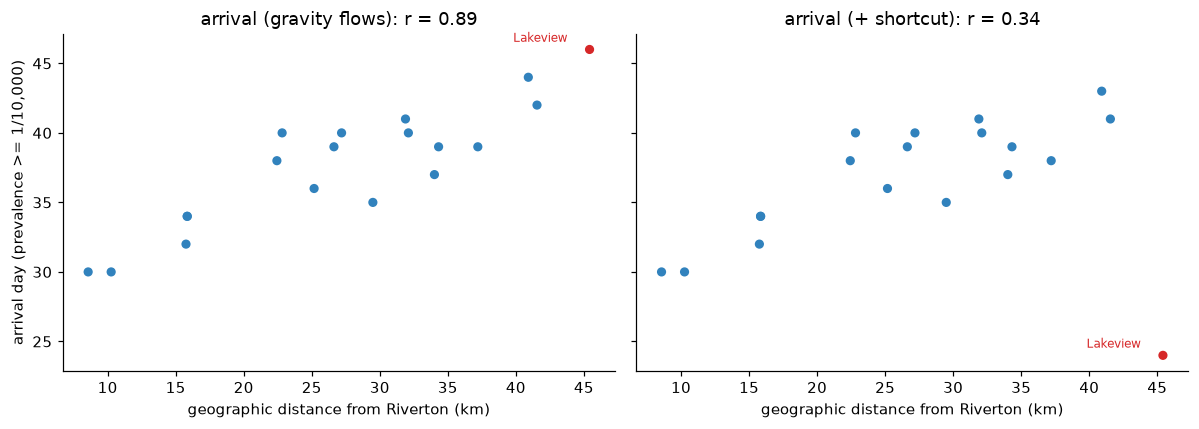

,geo_km,arrival (gravity flows),arrival (+ shortcut)
Lakeview,45.415208,46,24
Pine Hollow,8.565165,30,30
Millbrook,10.256130,30,30
Brookside,15.756371,32,32
Westover,15.850413,34,34


In [14]:
# ===================================================================
# Counterfactual: add a Riverton-Lakeview commuting shortcut and compare
# arrival times vs geographic distance (baseline vs shortcut).
# ===================================================================

C_short = C.copy()  # commuting matrix with the long-range shortcut
i, j = names_t.index("Riverton"), names_t.index("Lakeview")  # run this analysis or plotting step
C_short[i, j] += 200  # extra daily trips Riverton -> Lakeview
C_short[j, i] += 200  # and the return direction
arr_short = sna.arrival_times(  # arrival times with the shortcut added
    sna.metapopulation_sir(C_short, N, names_t.index(seed)),  # call a geolattice.network_analysis helper
    threshold=1e-4,  # distance-band threshold
    index=names_t,  # index argument
)

# Geographic km from the seed to every other town.
d_geo = pd.Series({  # geographic km from the seed town
    t: towns.loc[seed, "geometry"].distance(towns.loc[t, "geometry"]) / 1000 for t in names_t  # run this analysis or plotting step
})
res = pd.DataFrame({  # arrival-time comparison table
    "geo_km": d_geo,  # continue string literal
    "arrival (gravity flows)": arr,  # continue multi-line call
    "arrival (+ shortcut)": arr_short,  # continue multi-line call
}).drop(seed)  # seed has arrival day 0 by construction

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)  # create a grid of subplot axes
for ax, col in zip(axes, ["arrival (gravity flows)", "arrival (+ shortcut)"]):  # iterate paired sequences together
    r = np.corrcoef(res.geo_km, res[col])[0, 1]  # geo vs arrival correlation
    ax.scatter(  # plot point markers
        res.geo_km, res[col], s=25,  # notebook step
        c=np.where(res.index == "Lakeview", "#d62728", "#3182bd"),  # highlight Lakeview
    )
    ax.annotate(  # label a feature near its coordinates
        "Lakeview",  # continue string literal
        (res.loc["Lakeview", "geo_km"], res.loc["Lakeview", col]),  # continue multi-line call
        fontsize=8, color="#d62728",  # font size
        xytext=(-50, 5), textcoords="offset points",  # annotation text offset in points
    )
    ax.set(xlabel=f"geographic distance from {seed} (km)", title=f"{col}: r = {r:.2f}")  # set labels, title, or axis limits
axes[0].set_ylabel("arrival day (prevalence >= 1/10,000)")  # configure this subplot's labels or title
plt.tight_layout()  # reduce wasted whitespace between panels
plt.show()  # render the figure in the notebook
res.sort_values("arrival (+ shortcut)").head(5)  # run this analysis or plotting step



One strong long-range tie moves Lakeview from the last town to be reached to the first, and the correlation between geography and arrival time collapses. The same mechanism explains why airline networks, not distance, govern international spread, and why Brockmann & Helbing (2013) proposed **effective distance** $d_{ij} = 1 - \log P_{ij}$, built from the share $P_{ij}$ of travel from *i* to *j*, as a better predictor of arrival time in global mobility networks (Exercise 3 tests it here).

## Summary

- OD tables become directed weighted graphs; in-, out-, and net flows separate employment centers from dormitory towns.
- Flow maps need filtering (top *n*, removing dominant hubs) and curved arrows.
- Gravity models quantify distance decay; prefer **PPML** over OLS on log flows.
- Dominant flows reveal hierarchy; community detection reveals functional regions; PageRank measures attraction.
- Flows are contagion pathways: with distance-decayed flows spread follows geography, but a few long-range ties break that link.

### Exercises

1. Fit the gravity model with an **exponential** cost function ($e^{\gamma t}$, i.e., use minutes instead of log minutes). Which fits better?
2. Add origin and destination fixed effects (dummy variables) to the PPML model, the "doubly constrained" gravity model. What happens to γ?
3. Compute Brockmann-Helbing effective distance from Riverton (shortest paths on $1 - \log P_{ij}$) with and without the shortcut. Does it predict arrival better than geography here? Why might it underperform when many parallel short-range paths carry the infection?
4. Download ACS county-to-county commuting flows for New York State and reproduce Parts A and D2.

**Next:** 03.06.6 applies spatial network ideas to farmer information networks and agricultural technology diffusion.

